# Author: Lena Noack
# GNU General Public License v3.0 (GPL-3.0)
#Interior Structure Model


In [10]:
import numpy as np
import math
import csv
import pandas as pd
import matplotlib.pyplot as plt
import os

In [11]:
from EOS_functions import EOS_rock, EOS_core, EOS_core_mixed
from values import *
from Help_functions import get_Tmelt_MO, get_Tmelt_core, get_Tmelt_water, getphase
from water import getWater


# Start interior structure model with the temperature and pressure equation.

In [12]:
def temp_pla2(T_e, R_e, a):
    t_p=T_e*(R_e/(2*a))**(1/2)
    return t_p

# Units: 1, kg, kg, km, km, dimensionless 
def pressao(P_t, M_p, M_t, R_p, R_t, tipo): 
    if tipo == 1: #Mercury
        beta = 1.05*10**(-13)
    elif tipo == 0:#Venus
        beta = 108.27
    elif tipo == 2:#marte
        beta = 0.0467
    elif tipo==3 or tipo==4 : #Earth
        beta = 1.014
    else:#Any other type, I'll disregard those anyway.
        beta=1
    P=beta*((M_p/M_t)**2)*((R_t/R_p)**4)*P_t
    return P*101325

In [13]:
def interior_structure(M,x_Fe_tot,x_H2O_tot, t, P):
  '''
  input:
   M: Mass in Earth masses
   x_Fe_tot: Iron weigth fraction in percent of the entire planet (core + mantle)
   x_H2O_tot: Water weigth fraction in percent of surface water/ice layer
  return:
   Rp_E - planet radius in Earth radii
   MOI - moment of inertia factor
   radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu - profiles of different planetary properties
   mat - material layers (<0 ices, 0 water, >0 different rock and core layers)
  '''

  '''Set initialization parameters'''
  Dcr = 50e3      # thickness of crustal layer in m
  Dlid = 300e3    # thickness of lithosphere, only used to set upper mantle temperature
  Psurf = P     # atmospheric surface pressure
  Tsurf = t     # potential surface temperature in K
  Tlid = 0.0    #2000 # in K; if set to 0, then mantle melt temp is used at Dlid depth to set Tlid
  DTcmb = -1.0  #1500 # in K, T jump at CMB; if set to neg value (e.g. -1), then jump is calculated via melt temp times -DTcmb
  nr = 500         # radial resolution from center of planet to surface
  tol = 0.001     # Convergence parameter
  maxIter = 20   # max number iterations

  # light elements in the core -> array added for molar fractions Si,C,S,O; e.g. (0.2 S -> Fe0.8S0.2), means weight fraction of 12 wt-% S
  xelem = np.array([0.0,0.0,0.2,0.0]) # initial core-averaged value
  xelem_ic = np.array([0.00,0.00,0.07,0.00]) # fixed inner core value (no real partitioning included yet; outer core value calculated during inner core growth

  X_FeM_mol = 0.1 # iron number in mantle (ratio of Fe-bearing molecules divided by Mg- and Fe-bearing molecules)
  X_H2OM = 0      # water content in mantle in wt-%, only used for el cond profile versions 2-4
  ec_model = 1    # electrical conductivity profiles: 1 - Xu, 2 - mat-dep prof without Fe, 3 - as 2 but with Fe dependence, 4 - as 3 but newer parameters


  '''Distribute iron between core and mantle'''

  x_Fe_tot = x_Fe_tot/100 # weight fraction instead of percent
  x_H2O_tot = x_H2O_tot/100
  M = M * 5.972*10**24 # mass in kg
  Mw = M*x_H2O_tot 
  G = 6.67384*10**(-11) # gravitational constant in m^3 / (kg s^2)

  # Molar masses:
  mMg=24.305; mFe=55.845; mSi=28.0855; mO=15.9994

  XmFe = 2*X_FeM_mol*mFe/(X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) # mantle mass fraction of iron w.r.t. mantle mass

  
  x_Fe = ( x_Fe_tot*M - XmFe*(M-Mw) ) / (M*(1-XmFe)) # core mass fraction w.r.t. total planet mass
  Mc = x_Fe*M
  if Mc<0.0:
      raise ValueError(f"Not enough iron in planet to have {iron_number} as iron number")
      Mc = 0.0
      x_Fe = 0.0
      XmFe = x_Fe_tot*M / (M-Mw) # adapt XmFe such that all iron is in mantle

      #XmFe * (X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) = 2*X_FeM_mol*mFe
      X_FeM_mol = XmFe*(2*mMg+mSi+4*mO)/(2*mFe-2*(mFe-mMg)*XmFe) # adapt mantle iron number

  Mm = M - Mc - Mw

  '''Initialization routines'''

  rho_c = 11000 # guess for core density in kg/m^3
  rho_m = 4000 # guess for mantle density in kg/m^3
  rho_w = 1000 # guess for water density in kg/m^3
  cp_c = 800 # guess for core heat capacity in J/kg K
  cp_m = 1300 # guess for mantle heat capacity in J/kg K
  cp_w = 4200 # guess for water heat capacity in J/kg K
  alpha_c = 0.00001 # guess for core thermal expansion ceoff. in 1/K
  alpha_m = 0.000025 # guess for mantle thermal expansion ceoff. in 1/K
  alpha_w = 0.00007 # guess for water thermal expansion ceoff. in 1/K

  Rc = ( Mc*3.0 / (4.0*math.pi*rho_c) )**(1/3) # first guess core radius
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius
  Rp = ( Mw*3.0 / (4.0*math.pi*rho_w) + Rm**3 )**(1/3) # first guess planet radius

  # Define arrays
  dr = np.zeros(nr) # distance between radius points
  radius = np.zeros(nr) # vector of radii, first radius is dr
  pressure = np.zeros(nr)
  gravity = np.zeros(nr)
  temperature = np.zeros(nr)
  density = np.zeros(nr)
  alpha = np.zeros(nr)
  cp = np.zeros(nr)
  KT = np.zeros(nr)
  KS = np.zeros(nr)
  mu = np.zeros(nr)
  mass = np.zeros(nr)
  mat = np.zeros(nr)
  elcond = np.zeros(nr)

  # set number of grid points in the three layers (core/mantle/water) based on initial radii, to be kept constant throughout iteration
  nc = int(nr * Rc/Rp)
  if (x_H2O_tot==0):
    nm = nr - nc
    nw = 0
  else:
    nm = int(nr * Rm/Rp) - nc
    nw = nr - nm - nc

  # Initialization of arrays: surface values
  if Mw>0:
    density[nr-1] = rho_w
    alpha[nr-1] = alpha_w
    cp[nr-1] = cp_w
  elif Mm>0:
    density[nr-1] = rho_m
    alpha[nr-1] = alpha_m
    cp[nr-1] = cp_m
  else: # pure iron shell
    density[nr-1] = rho_c
    alpha[nr-1] = alpha_c
    cp[nr-1] = cp_c
    Rc = Rp

  # Initialization of arrays: interpolation over depth
  for i in range(0,nr):
    if i==0:
      r_prev = 0.0
    else:
      r_prev = radius[i-1]
    if i<nc:
      dr[i] = Rc/float(nc)
      density[i] = rho_c
      alpha[i] = alpha_c
      cp[i] = cp_c
    elif i<nc+nm:
      dr[i] = (Rm-Rc)/float(nm)
      density[i] = rho_m
      alpha[i] = alpha_m
      cp[i] = cp_m
    else:
      dr[i] = (Rp-Rm)/float(nw)
      density[i] = rho_w
      alpha[i] = alpha_w
      cp[i] = cp_w
    radius[i] = r_prev + dr[i]


  # pressure and temperature are interpolated from surface downwards
  # gravity has boundary condition 0 in center (and not at surface)
  pressure[nr-1] = Psurf # 1 bar surface pressure
  temperature[nr-1] = Tsurf # surface temperature
  gravity[nr-1] = G*M/Rp**2 # first guess surface gravity
  plid = Dlid*rho_m*gravity[nr-1] # first guess at plid, will be calculated below


  '''Start iteration to determine interior structure'''

  iter = 1
  Store_V_vec_old = []
  Rp_old = 0
  while (abs(Rp-Rp_old) > tol) and (iter < maxIter):
      # store old Rp value to determine convergence
      Rp_old = Rp

      # average values will be re-determined from material properties
      rho_c = 0; rho_m = 0; rho_w = 0; vol_c = 0; vol_m = 0; vol_w = 0

      # update vectors for radius, gravity, pressure and temperature
      for i in range(0,nr):
        if i==0:
          r_prev = 0.0
        else:
          r_prev = radius[i-1]
        if i<nc:
          dr[i] = Rc/float(nc)
        elif i<nc+nm:
          dr[i] = (Rm-Rc)/float(nm)
        else:
          dr[i] = (Rp-Rm)/float(nw)
        radius[i] = r_prev + dr[i]

      
      gravity[0] = radius[0] * 4/3*math.pi*G*density[0]
      for i in range(1,nr):
          gravity[i] = gravity[i-1] + dr[i-1] * (4*math.pi*G*density[i-1] - 2*gravity[i-1]/radius[i-1])

      for i in range(nr-2,-1,-1):
          pressure[i] = pressure[i+1] + dr[i]*gravity[i]*density[i]
          if i>=nc+nm: # ocean layer, we assume here adiabatic profile from the surface
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          elif Rm-radius[i]<Dlid: # in lithosphere
              if Mw>0:
                Ts = temperature[nc+nm]
              else:
                Ts = Tsurf
              if Tlid>0:
                  
                  temperature[i] = Ts + (Tlid-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
              else:
                  temperature[i] = Ts + (get_Tmelt_MO(plid)-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
          elif Rm-radius[i+1]<Dlid: # first grid point in mantle
              if Tlid>0:
                  temperature[i] = Tlid 
              else:
                  temperature[i] = get_Tmelt_MO(plid) 
              plid = pressure[i] 
          elif (i+1==nc):
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
              if DTcmb >= 0:
                  
                  temperature[i] = temperature[i] + DTcmb
              else:
                  
                  temperature[i] = temperature[i] + (get_Tmelt_MO(pressure[i])-temperature[i]) * abs(DTcmb)
          else: 
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          
      Store_V_vec = []
      ric = 0
      for i in range(nr): # from center to surface
          # get correct layer depending on core size, mantle phase transitions, and crust thickness
          # 7 layers in total: 6-core, 5-ppv, 4-pv, 3-ri, 2-wa, 1-ol, 0-cr
          if i < nc:
              # iron core
              if temperature[i]<get_Tmelt_core(pressure[i]):
                mat[i] = 8 # inner core
                ric = radius[i] # updated until outer core is reached
              else:
                mat[i] = 7 # outer core
              arr_species = ['fehcp']
              mole_vec = [1]
          elif i >= nc+nm:
              # water layer
              mat[i] = 0 # liquid water or water ice, phase defined below
              arr_species = ['h2o']
              [Tm,phase] = get_Tmelt_water(pressure[i])
              if temperature[i]<Tm:
                mat[i] = -phase # ice phases stored with negative values
              mole_vec = [1]
          elif pressure[i] >= (127 + 0.006*(temperature[i]-2840))*10**9:
              # post-perovskite
              mat[i] = 6
              arr_species = ['mppv', 'fppv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif pressure[i] >= (22.9 - 0.0025*(temperature[i]-2260))*10**9:
              # perovskite
              mat[i] = 5
              arr_species = ['mgpv', 'fepv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif (pressure[i] >= (6.2 + 16.7*(1-X_FeM_mol) + 0.005*(temperature[i]-2260))*10**9) & (radius[i] <= Rm-Dcr):
              # ringwoodite
              mat[i] = 4
              arr_species = ['mgri', 'feri']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif (pressure[i] >= (4.92 + 5.4*(1-X_FeM_mol) + 0.0025*temperature[i])*10**9) & (radius[i] <= Rm-Dcr):
              # wadsleyite
              mat[i] = 3
              arr_species = ['mgwa', 'fewa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif radius[i] <= Rm-Dcr:
              # olivine
              mat[i] = 2
              arr_species = ['fo', 'fa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          else:
              # crust
              mat[i] = 1
              arr_species = ['an','di','qtz'] #Anorthite Feldspar Ca[Al2Si2]O8; Diopside CaMgSi2O6; Quartz SiO2
              mole_vec = [0.5, 0.25, 0.25]

          # mole fraction to mass fraction
          molmass = np.zeros(len(mole_vec))
          for k,species in enumerate(arr_species):
              res = values(species) # params for species
              molmass[k] = res.M
          mf_vec = mole_vec*molmass / np.sum(mole_vec*molmass)


         
          if mat[i] >= 7:
              if mat[i] == 8:
                xelemc = xelem_ic
              else:
                xelemc = (xelem * radius[nc-1]**3 - xelem_ic*ric**3)/(radius[nc-1]**3-ric**3) 
              
              cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_core_mixed(pressure[i]/10**9,temperature[i],xC=xelemc[1], xSi=xelemc[0], xS=xelemc[2], xO=xelemc[3])

          else:
              if Store_V_vec_old == []:
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec)
              else:
                 
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec,Store_V_vec_old[i])
          Store_V_vec.append(V_vec)

          # check profiles
          # update mass vector (used here only for visualization)
          if i==0:
              mass[i] = 4*math.pi*radius[i]**3*density[i]
          else:
              mass[i] = mass[i-1] + (radius[i]-radius[i-1])*4*math.pi*radius[i]**2*density[i]

          #Get new average densities for radius update
          if i==0:
              vol = 4/3 * math.pi * radius[i]**3
          else:
              vol = 4/3 * math.pi * (radius[i]**3 - radius[i-1]**3)

          if i <= nc:
              rho_c = rho_c + density[i]*vol
              vol_c = vol_c + vol
          elif i <= nc+nm:
              rho_m = rho_m + density[i]*vol
              vol_m = vol_m + vol
          else:
              rho_w = rho_w + density[i]*vol
              vol_w = vol_w + vol

      # Error with surface density for iron incl. light species
      if density[nr-1] < 0:
          density[nr-1] = density[nr-2]

      Store_V_vec_old = Store_V_vec

      if vol_c==0:
          vol_c=1 # in case that no core exists
      if vol_m==0:
          vol_m=1 # in case that no mantle exists
      if vol_w==0:
          vol_w=1 # in case that no water layer exists

      rho_c = rho_c / vol_c
      rho_m = rho_m / vol_m
      rho_w = rho_w / vol_w

      # update radius for core and mantle
      if Mc==0:
        Rc = 0
      else:
        Rc = (3*Mc/(4*math.pi*rho_c))**(1/3)
      if Mm==0:
        Rm = Rc
      else:
        if (rho_m>0.0):
          Rm = (Rc**3 + 3*Mm/(4*math.pi*rho_m))**(1/3)
        else:
          Rm = Rc
      if Mw==0:
        Rp = Rm
      else:
        if (rho_w>0.0): # can happen if surface water layer is smaller than resolution between two uppermost grid points
          Rp = (Rm**3 + 3*Mw/(4*math.pi*rho_w))**(1/3)
        else:
          Rp = Rm

      #print('{0:2d} {1:8.2f} {2:8.2f} {3:7.1f} {4:7.1f}'.format(iter,Rp/1000,Rc/1000,rho_m,rho_c))

      iter=iter+1


  '''Post-processing'''

  # Additional properties computed from final iteration (i.e. without influence on interior structure)

  # seismic velocity profiles
  vP = np.sqrt((KS*10**9+4/3*mu*10**9)/density)*10**-3 # in km/s
  vS = np.sqrt(mu*10**9/density)*10**-3 # in km/s

  # electrical conductivity
  kB = 8.61733e-5
  for i in range(nr):
      T = temperature[i]

      if mat[i]<=0:
          elcond[i] = 1.0e-20
      elif mat[i]<=2: # olivine layer and crust
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.69*math.exp(-1.62/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**2.98*X_FeM_mol*math.exp(-(1.71-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==3): # wadsleyite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**3.29*math.exp(-1.29/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 399.0*math.exp(-1.49/(kB*T)) \
              + 7.74*X_H2OM*math.exp(-(0.68-0.02*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.46*X_FeM_mol*math.exp(-(1.45-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.4*X_H2OM*math.exp(-(0.83-0.2*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==4): # ringwoodite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.92*math.exp(-1.16/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 838.0*math.exp(-1.36/(kB*T)) \
              + 27.7*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          elif ec_model==3:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with enthalpy and alpha from Yoshino&Katsura 2009
              elcond[i] = 10042*X_FeM_mol*math.exp(-(2.48-2.25*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.92*X_FeM_mol*math.exp(-(1.36-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==5) or (mat[i]==6): # pv or ppv layer
          #  Xu 2000 lower mantle values (for pv, use here the same formula for ppv)
          elcond[i] = 0.6851*10**1.12*math.exp(-0.62/(kB*T)) \
                    + 0.3149*10**2.69*math.exp(-0.85/(kB*T))
      else: # profile not calculated for core, does not matter anyway for induction heating
          elcond[i] = math.nan

  # log10 values; in iron core ec=nan -> log profile is also nan
  elcond = np.log10(elcond)

  # moment of inertia factor

  IntVal = 0
  for i in range(nr):
    IntVal += density[i] * (radius[i]-0.5*dr[i])**4 * dr[i]

  MOI = IntVal * 8*math.pi/(3*M*Rp**2)

  # radius in Earth radii instead of m
  Rc_E = Rc / 6371000
  Rp_E = Rp / 6371000
  Rm_E = Rm / 6371000

  return Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat

# Visualization function

In [14]:
def visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(5,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  # add PREM values (radius,density,Vpv,Vsv,Q-kappa,Q-mu,Vph,Vsh,eta)
  PREM = np.loadtxt('PREM500.csv',delimiter=",") # doi:10.17611/DP/10131390
  ax[0,0].plot(PREM[:,0]/1000, PREM[:,1], ':', color='black', alpha=1, label="PREM")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")

  ax[2,0].plot(radius/1000, alpha*10**5, color='black', alpha=1)
  ax[2,0].set_title("Alpha")
  ax[2,0].set_ylabel("Thermal expansion in $10^{-5}$/K")

  ax[2,1].plot(radius/1000, cp, color='black', alpha=1)
  ax[2,1].set_title("Cp")
  ax[2,1].set_ylabel("Heat capacity in W/mK")

  ax[3,0].plot(radius/1000, mass, color='black', alpha=1)
  ax[3,0].set_title("Mass")
  ax[3,0].set_ylabel("Mass in kg")

  ax[3,1].plot(radius/1000, elcond, color='black', alpha=1)
  ax[3,1].set_title("Electrical Conductivity")
  ax[3,1].set_ylabel("Log10 Electrical Conductivity in S")
  ax[3,1].set_ylim([-4,2])

  ax[4,0].plot(radius/1000, vP, color='black', alpha=1, label='vP')
  ax[4,0].plot(radius/1000, vS, ':', color='black', alpha=1, label='vS')
  ax[4,0].set_title("Seismic velocities")
  ax[4,0].legend()
  ax[4,0].set_ylabel("Velocity in km/s")
  ax[4,0].set_xlabel("Radius in km")

  ax[4,1].plot(radius/1000, KT, color='black', alpha=1, label='KT')
  ax[4,1].plot(radius/1000, KS, ':', color='black', alpha=1, label='KS')
  ax[4,1].plot(radius/1000, mu, '--', color='black', alpha=1, label='mu')
  ax[4,1].legend()
  ax[4,1].set_title("Bulk and shear modulus")
  ax[4,1].set_ylabel("Modulus in GPa")
  ax[4,1].set_xlabel("Radius in km")

  for i in range(5):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

  # print(mat)

In [15]:
def visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(5,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")

  ax[2,0].plot(radius/1000, alpha*10**5, color='black', alpha=1)
  ax[2,0].set_title("Alpha")
  ax[2,0].set_ylabel("Thermal expansion in $10^{-5}$/K")

  ax[2,1].plot(radius/1000, cp, color='black', alpha=1)
  ax[2,1].set_title("Cp")
  ax[2,1].set_ylabel("Heat capacity in W/mK")

  ax[3,0].plot(radius/1000, mass, color='black', alpha=1)
  ax[3,0].set_title("Mass")
  ax[3,0].set_ylabel("Mass in kg")

  ax[3,1].plot(radius/1000, elcond, color='black', alpha=1)
  ax[3,1].set_title("Electrical Conductivity")
  ax[3,1].set_ylabel("Log10 Electrical Conductivity in S")
  ax[3,1].set_ylim([-4,2])

  ax[4,0].plot(radius/1000, vP, color='black', alpha=1, label='vP')
  ax[4,0].plot(radius/1000, vS, ':', color='black', alpha=1, label='vS')
  ax[4,0].set_title("Seismic velocities")
  ax[4,0].legend()
  ax[4,0].set_ylabel("Velocity in km/s")
  ax[4,0].set_xlabel("Radius in km")

  ax[4,1].plot(radius/1000, KT, color='black', alpha=1, label='KT')
  ax[4,1].plot(radius/1000, KS, ':', color='black', alpha=1, label='KS')
  ax[4,1].plot(radius/1000, mu, '--', color='black', alpha=1, label='mu')
  ax[4,1].legend()
  ax[4,1].set_title("Bulk and shear modulus")
  ax[4,1].set_ylabel("Modulus in GPa")
  ax[4,1].set_xlabel("Radius in km")

  for i in range(5):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

  # print(mat)

# Example 1: Earth Reproduction

In [16]:
from astropy import constants as const
from astropy import units as u

# Constantes
r_s = const.R_sun.to(u.au).value.item() #UA
m_s= const.M_sun.to(u.kg).value.item() #kg
T_sol=5772 #K
M_t= const.M_earth.to(u.kg).value.item() #kg
R_t= const.R_earth.to(u.km).value.item() #km
P_t= 1 #atm
UA=1.496e+11#m
R_sol=6.96*10**8 #m

In [17]:
T_p=temp_pla2(T_sol, r_s, 1)
P_p=pressao(1, 1, 1, 1, 1, 3)

In [18]:
T_p, P_p

(278.3297440615529, 102743.55)


1.0000 Earth masses with 38.00% iron leads to planet radius 1.0012 (6378 km) with MOI factor 0.331


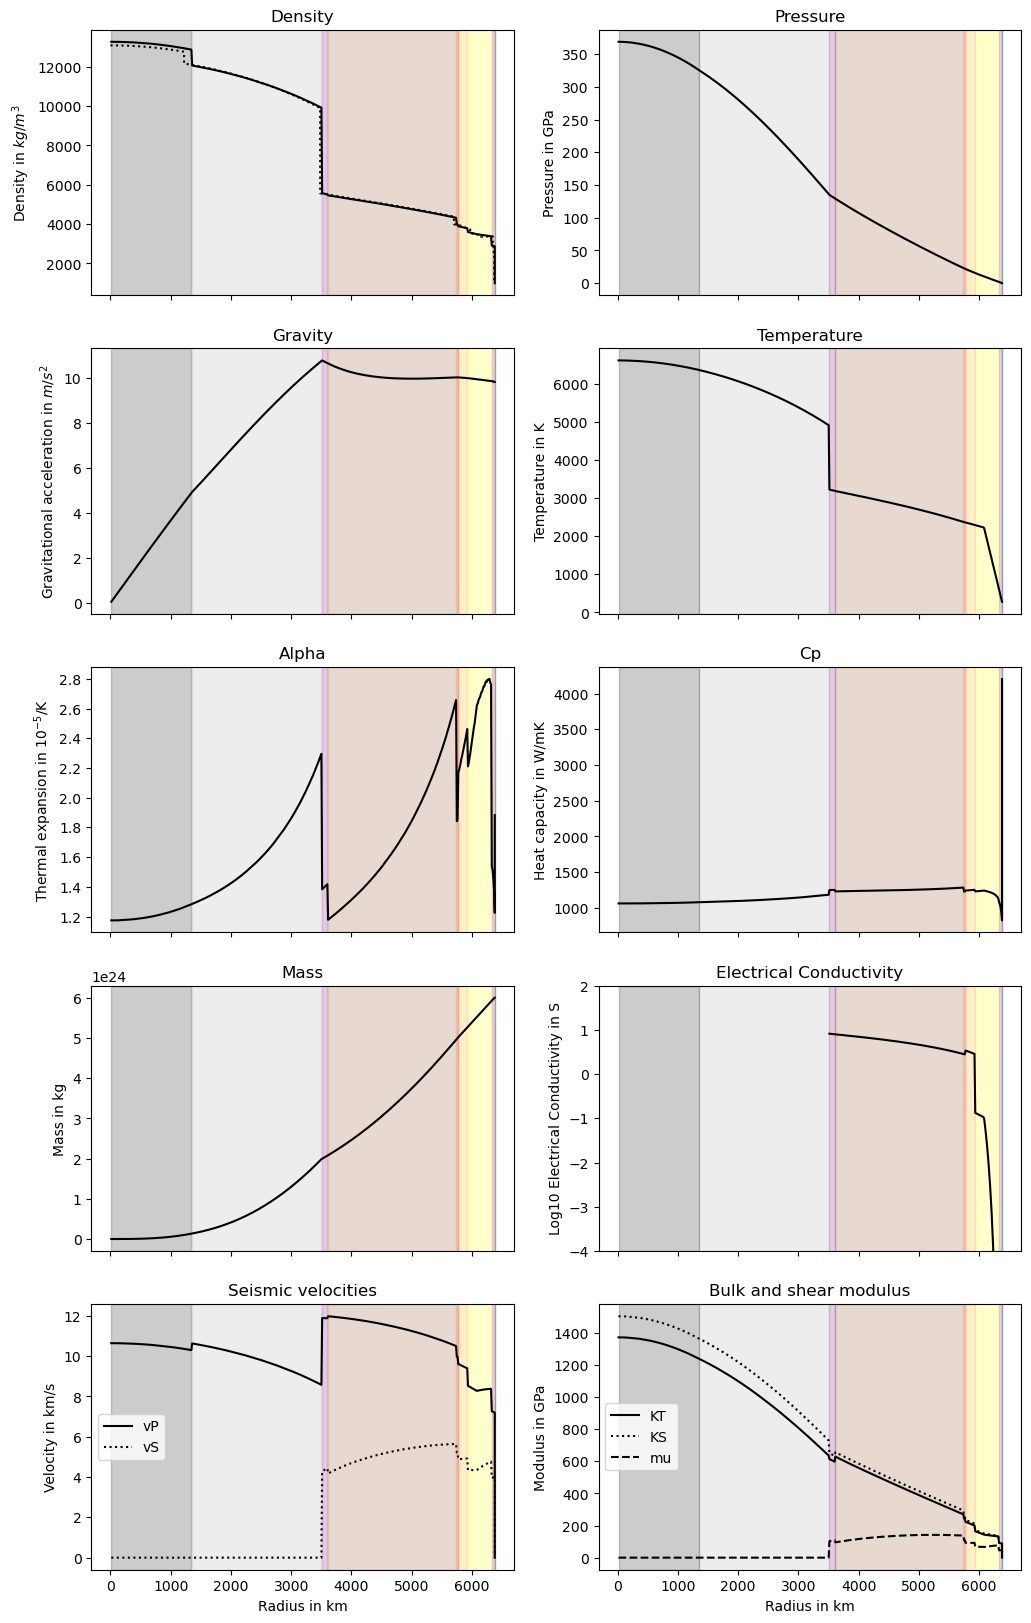

In [21]:
M=1; x_Fe_tot=38; x_H2O_tot=0.023
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [22]:
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



In [23]:
# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

In [24]:
depth = 2500e3                                           # m
i = np.argmin(np.abs(radius - (radius[-1] - depth)))
T_2500 = temperature[i]

In [14]:
T_2500, T_cmb_manto,T_cmb_nucleo , (Rc+Ric)/1000, rho_core_mean, Rp_E

(np.float64(3219.9977345438324),
 np.float64(4908.786976723047),
 np.float64(4856.795746741388),
 np.float64(11168.21137912287),
 np.float64(1.001178068261509))


1.0000 Earth masses with 38.50% iron leads to planet radius 0.9997 (6368 km) with MOI factor 0.330


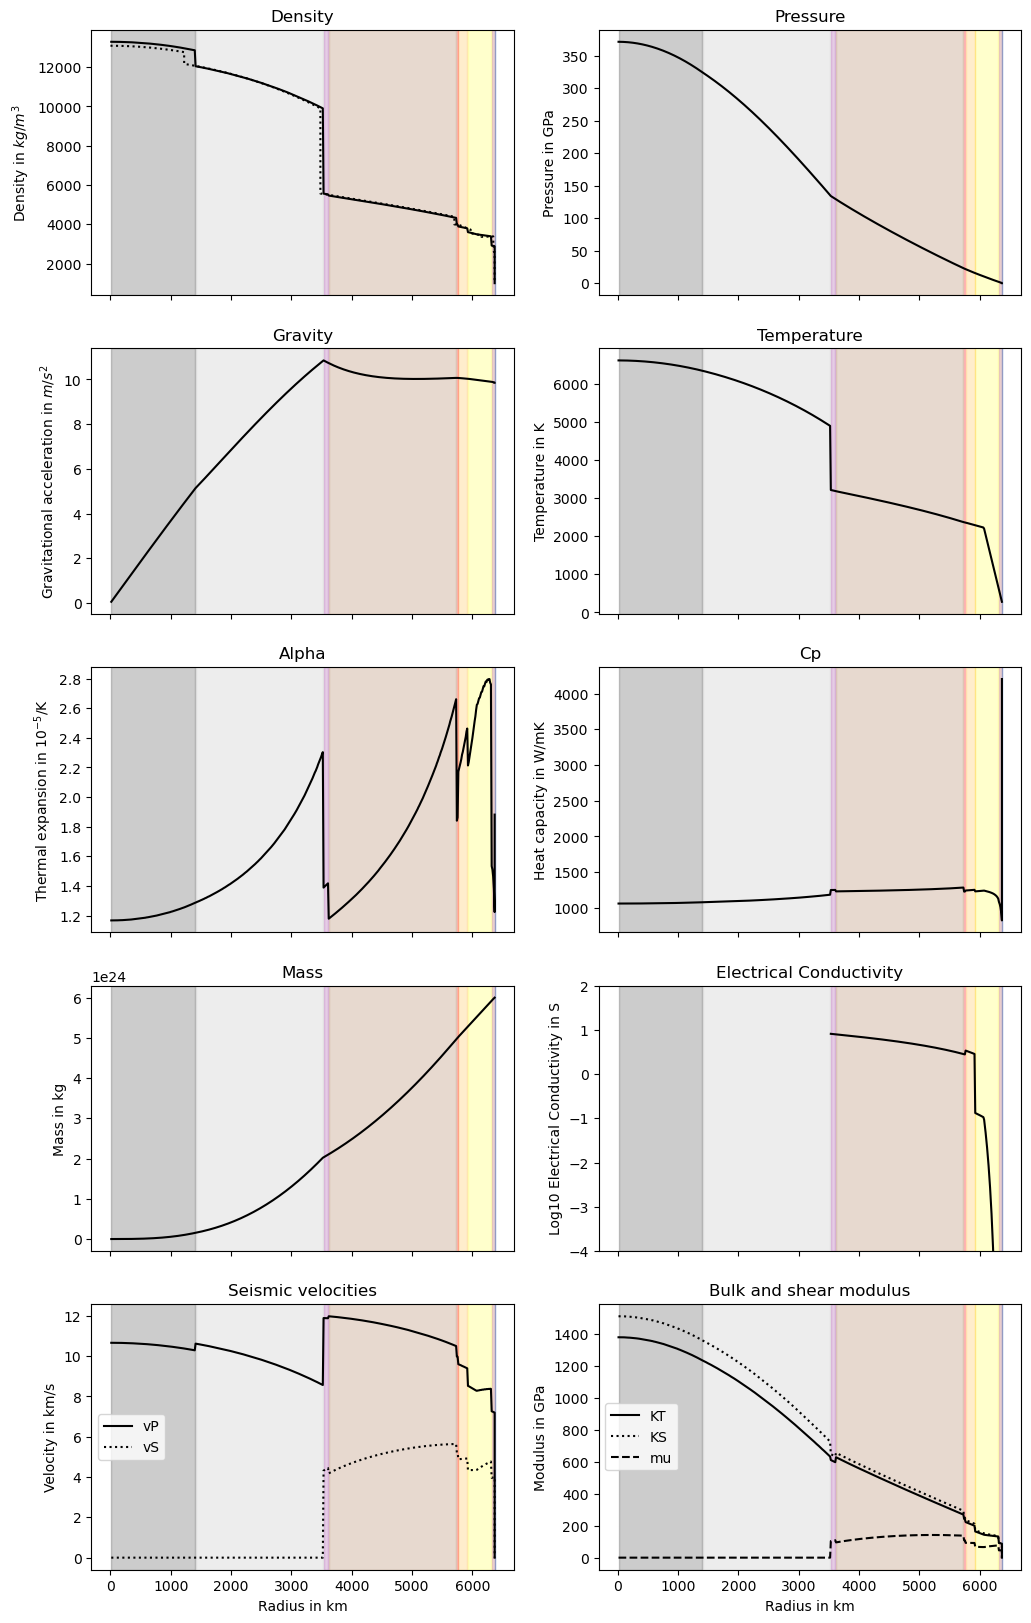

In [15]:
M=1; x_Fe_tot=38.5; x_H2O_tot=0.1
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

In [16]:
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


In [19]:
depth = 2500e3                                           # m
i = np.argmin(np.abs(radius - (radius[-1] - depth)))
T_2500 = temperature[i]

In [20]:
T_2500

np.float64(3100.0063207109533)

In [17]:
T_cmb_manto,T_cmb_nucleo , (Rc+Ric)/1000, rho_core_mean, Rp_E

(np.float64(3213.4410291049194),
 np.float64(4896.620814628851),
 np.float64(4931.114694320059),
 np.float64(11145.459057012808),
 np.float64(0.9996620967725922))

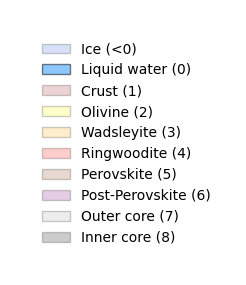

# Optimized likelihood function for estimating Fe and H2O using grid search in the ROWS model.

# APPLICATION FOR OTHER TERRESTRIAL OR SUPERTERRANEAN TYPE EXOPLANTS

In [19]:
resultados={'name':[], 'rho_core_mean':[], 'cp_core_mean':[], 'T_cmb':[], 'P_cmb':[],'Ric':[] ,'Rc':[] ,'D':[]}

In [20]:
mass_obs = 1.08 
radius_obs = 1.03
temp_obs = 288
P_p=1.05*10**5

In [21]:
name='GJ 1002 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.13288981803696975
0.5128716414864293
11482.89213944592


In [22]:
mass_obs = 1.36
radius_obs = 1.1
temp_obs = 242
P_p=1.28*10**5

In [23]:
name='GJ 1002 c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.18183649499418356
0.5103819802677638
11916.286658502717


In [24]:
mass_obs = 1.74
radius_obs = 1.18
temp_obs = 354
P_p=1.58*10**5

In [25]:
name='GJ 1061 c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.20531793463122397
0.5071352985391233
12507.696659159767


In [26]:
mass_obs = 1.64
radius_obs = 1.16
temp_obs = 293
    
P_p=1.51*10**5

In [27]:
name='GJ 1061 c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.40, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.22570470952148552
0.5170689709037655
12285.026858992416


In [28]:
mass_obs = 2.89
radius_obs = 1.51
temp_obs = 347
    
P_p=1.63*10**5

In [29]:
name='GJ 273 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 9.7, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.1847284418520046
13316.152627153106


In [30]:
mass_obs = 2.02
radius_obs = 1.23
temp_obs = 351
    
P_p=1.81*10**5

In [31]:
name='GJ 3323 B'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs,34.50 , 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.23904930643830324
0.5148754292517291
12840.110539487097


In [32]:
mass_obs = 4.4
radius_obs = 1.93
temp_obs = 329
    
P_p=1.41*10**5

In [33]:
name='GJ 682 B'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 70.85, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0
    
# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2547879856358296
14471.951148696726


In [34]:
mass_obs = 4.27
radius_obs = 1.9
temp_obs = 273
    
P_p=1.42*10**5

In [35]:
name='K2-288 B b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 67.925, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.25331175902415926
14429.382575912463


In [37]:
mass_obs = 2.21
radius_obs = 1.29
temp_obs = 346
    
P_p=1.79*10**5

In [38]:
name='K2-72 e'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 23.0, 0.125, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.4189299195964027
13510.346708268944


In [39]:
mass_obs = 2.54
radius_obs = 1.4
temp_obs = 295
    
P_p=1.7*10**5

In [40]:
name='Kepler 1229 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs,8.50 , 0.15, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.15893550636900086
12821.75709439883


In [41]:
mass_obs = 0.43
radius_obs = 0.797
temp_obs = 335
P_p=0.46*10**5

In [42]:
name='Kepler-138 e'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 28.75, 0.125, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.48484242514408116
9776.810877305883


In [43]:
mass_obs = 3.82
radius_obs = 1.78
temp_obs = 353
P_p=1.47*10**5

In [44]:
name='Kepler 1410 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 47.70, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2364127180037754
14315.472021934198


In [45]:
mass_obs = 3.82
radius_obs = 1.78
temp_obs = 324
    
P_p=1.47*10**5

In [46]:
name='Kepler 1544 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 47.70, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2364121943176445
14315.575475581472


In [47]:
mass_obs = 4.94
radius_obs = 2.07
temp_obs = 348
    
P_p=1.35*10**5

In [48]:
name='Kepler 1606 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 90.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.26870693419916575
13982.941072518386


In [49]:
mass_obs = 4.16
radius_obs = 1.87
temp_obs = 360
    
P_p=1.44*10**5

In [50]:
name='Kepler-1638 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 60.90 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2469618367576541
14473.554567137493


In [51]:
mass_obs = 1.2
radius_obs = 1.06
temp_obs = 334
    
P_p=1.16*10**5

In [52]:
name='Kepler-1649 c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.1947838373203592
0.5221864574971363
11589.675759618647


In [53]:
mass_obs = 3.19
radius_obs = 1.6
temp_obs = 320
    
P_p=1.57*10**5

In [54]:
name='Kepler-1652 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 20.0, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.203483888439042
13697.631110006896


In [55]:
mass_obs = 1.71
radius_obs = 1.17
temp_obs = 253
    
P_p=1.58*10**5

In [56]:
name='Kepler-186 f'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 35.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.23836759219172604
0.5219428311784357
12363.222127807981


In [57]:
mass_obs = 3.97
radius_obs = 1.82
temp_obs = 320   
P_p=1.46*10**5

In [58]:
name='Kepler-283 c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 54.50, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")

print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.24256004799800865
14389.333619377763


In [59]:
mass_obs = 2.96
radius_obs = 1.53
temp_obs = 359
    
P_p=1.62*10**5

In [60]:
name='Kepler-296 e'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 11.65, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.18875684242529076
13407.205261717618


In [61]:
mass_obs = 3.89
radius_obs = 1.8
temp_obs = 297
    
P_p=1.46*10**5

In [62]:
name='Kepler-296 f'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 51.50, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")

print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.24002844469037699
14346.441438836051


In [63]:
mass_obs = 4.12
radius_obs = 1.86
temp_obs = 352
    
P_p=1.44*10**5

In [64]:
name='Kepler-440 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 59.950 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.24650334291626733
14452.10155551754


In [66]:
mass_obs = 3.33
radius_obs = 1.64
temp_obs = 247
    
P_p=1.55*10**5

In [67]:
name='Kepler-441 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs,8.50 , 26.875, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2142010360813685
13866.212945713814


In [68]:
mass_obs = 2.36
radius_obs = 1.34
temp_obs = 316
    
P_p=1.75*10**5

In [69]:
name='Kepler-442 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 11.5, 0.125 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.26257897988151846
12975.735106128092


In [70]:
mass_obs = 3.29
radius_obs = 1.63
temp_obs = 339
    
P_p=1.55*10**5

In [71]:
name='Kepler-452 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 24.625 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2106033102702758
13819.03128729095


In [72]:
mass_obs = 2.8
radius_obs = 1.48
temp_obs = 341
    
P_p=1.66*10**5

In [73]:
name='L 98-59 f'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 5.825, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.17509518367926585
13186.924106727314


In [74]:
mass_obs = 5.6
radius_obs = 1.73
temp_obs = 346

P_p=3.55*10**5

In [75]:
name='LHS 1140 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 17.25, 4.70 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.3397492811418497
17224.832202514353


In [76]:
mass_obs = 1.055
radius_obs = 1.02
temp_obs = 274
    
P_p=1.04*10**5

In [77]:
name='Proxima Cen b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 36.75, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.20836524586223262
0.5384488036637893
11280.48544259486


In [78]:
mass_obs = 1.4
radius_obs = 1.11
temp_obs = 351
    
P_p=1.31*10**5

In [79]:
name='Ross 128 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.21430301268478158
0.5192726845823586
11905.907316032271


In [80]:
mass_obs = 4
radius_obs = 1.83
temp_obs = 343
    
P_p=1.45*10**5

In [81]:
name='Ross 508 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 52.825, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.23946420847963254
14441.571273235475


In [82]:
mass_obs = 3.68
radius_obs = 1.74
temp_obs = 338
    
P_p=1.5*10**5

In [83]:
name='TOI-1266 d'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5,41.8 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.23108581076474222
14216.19348436285


In [84]:
mass_obs = 1.25
radius_obs = 1.073
temp_obs = 308
    
P_p=1.2*10**5

In [85]:
name='TOI-700 d'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50,0.10 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.20071683684572475
0.5214499266507504
11669.204089546256


In [86]:
mass_obs = 0.818
radius_obs = 0.953
temp_obs = 323
    
P_p=0.82*10**5

In [87]:
name='TOI-700 e'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50, 0.10 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.5243198754675785
11097.504649385688


In [88]:
mass_obs = 3.02
radius_obs = 1.55
temp_obs = 306
    
P_p=1.6*10**5

In [89]:
name='TOI-715 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 14.55, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.19464173770012325
13489.00214022731


In [90]:
mass_obs = 1.16
radius_obs = 1.05
temp_obs = 353
    
P_p=1.12*10**5

In [91]:
name='Teegardens Star b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50,0.1 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.1886657495868971
0.5224589988560246
11526.963692003677


In [92]:
mass_obs = 1.05
radius_obs = 1.02
temp_obs = 273
    
P_p=1.03*10**5

In [93]:
name='Teegardens Star c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 35.0, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.17426600334391026
0.526947200587536
11344.521224596221


In [94]:
mass_obs = 3.41
radius_obs = 1.66
temp_obs = 352
    
P_p=1.55*10**5

In [95]:
name='Wolf 1061 c'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50,28.375 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.21558133021038617
13956.654320572554


In [96]:
mass_obs = 1.26
radius_obs = 1.08
temp_obs = 290
    
P_p=1.18*10**5

In [97]:
name='Wolf 1069 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.171213044765254
0.5095135187592523
11752.925124765301


In [98]:
mass_obs = 3.93
radius_obs = 1.81
temp_obs = 251
    
P_p=1.46*10**5

In [99]:
name='tau Cet f'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 53.750 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.24230619365811237
14359.599051692407


In [100]:
mass_obs = 8.92
radius_obs = 2.37
temp_obs = 317
    
P_p=2.56*10**5

In [101]:
name='K2-18 b'
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 9.50, 84.80, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
    D = Rc - Ric
else:
    
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Ric = radius[all_core_indices[-1]]
    Rc = 0
    D=0
    
# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
    P_cmb=pressure[outer_core_indices[-1]]
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(rho_core_mean)
    resultados['cp_core_mean'].append(cp_core_mean)
    resultados['T_cmb'].append(T_cmb)
    resultados['P_cmb'].append(P_cmb)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
else:
    resultados['name'].append(name)
    resultados['rho_core_mean'].append(np.nan)
    resultados['cp_core_mean'].append(np.nan)
    resultados['T_cmb'].append(np.nan)
    resultados['P_cmb'].append(np.nan)
    resultados['Ric'].append(Ric)
    resultados['Rc'].append(Rc)
    resultados['D'].append(D)
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2737850106203413
17204.232765157296


In [102]:
resultados

{'name': ['GJ 1002 b',
  'GJ 1002 c',
  'GJ 1061 c',
  'GJ 1061 c',
  'GJ 273 b',
  'GJ 3323 B',
  'GJ 682 B',
  'K2-288 B b',
  'K2-72 e',
  'Kepler 1229 b',
  'Kepler-138 e',
  'Kepler 1410 b',
  'Kepler 1544 b',
  'Kepler 1606 b',
  'Kepler-1638 b',
  'Kepler-1649 c',
  'Kepler-1652 b',
  'Kepler-186 f',
  'Kepler-283 c',
  'Kepler-296 e',
  'Kepler-296 f',
  'Kepler-440 b',
  'Kepler-441 b',
  'Kepler-442 b',
  'Kepler-452 b',
  'L 98-59 f',
  'LHS 1140 b',
  'Proxima Cen b',
  'Ross 128 b',
  'Ross 508 b',
  'TOI-1266 d',
  'TOI-700 d',
  'TOI-700 e',
  'TOI-715 b',
  'Teegardens Star b',
  'Teegardens Star c',
  'Wolf 1061 c',
  'Wolf 1069 b',
  'tau Cet f',
  'K2-18 b'],
 'rho_core_mean': [np.float64(11482.89213944592),
  np.float64(11916.286658502717),
  np.float64(12507.696659159767),
  np.float64(12285.026858992416),
  np.float64(13316.152627153106),
  np.float64(12840.110539487097),
  np.float64(14471.951148696726),
  np.float64(14429.382575912463),
  np.float64(13510.346708

In [103]:
import pandas as pd

In [104]:
df_resultados=pd.DataFrame(resultados)

In [105]:
df_resultados

,name,rho_core_mean,cp_core_mean,T_cmb,P_cmb,Ric,Rc,D
0,GJ 1002 b,11482.892139,1118.696379,5152.454319,1.541490e+11,8.730121e+05,3.369281e+06,2.496269e+06
1,GJ 1002 c,11916.286659,1126.673480,5647.774895,1.905501e+11,1.275748e+06,3.580794e+06,2.305046e+06
2,GJ 1061 c,12507.696659,1132.344863,6273.681386,2.401044e+11,1.545255e+06,3.816780e+06,2.271525e+06
3,GJ 1061 c,12285.026859,1131.787104,6074.636361,2.238259e+11,1.669898e+06,3.825584e+06,2.155686e+06
4,GJ 273 b,13316.152627,1180.433221,8375.730517,4.447848e+11,0.000000e+00,1.779107e+06,1.779107e+06
5,GJ 3323 B,12840.110539,1134.549617,6655.606611,2.727905e+11,1.875357e+06,4.039230e+06,2.163873e+06
6,GJ 682 B,14471.951149,1145.104373,8787.924878,4.921302e+11,0.000000e+00,3.136372e+06,3.136372e+06
7,K2-288 B b,14429.382576,1147.030458,8799.172022,4.934554e+11,0.000000e+00,3.069731e+06,3.069731e+06
8,K2-72 e,13510.346708,1133.996093,7263.863212,3.289222e+11,0.000000e+00,3.446850e+06,3.446850e+06
9,Kepler 1229 b,12821.757094,1188.510486,7945.184159,3.978723e+11,0.000000e+00,1.419189e+06,1.419189e+06


In [106]:
df=pd.read_csv('dados fe artigo - Página1.csv')

In [107]:
def encontrar_x(df: pd.DataFrame, temperatura: float, pressao: float) -> str:
    """
    Retorna o parâmetro X do DataFrame cujo ponto (T, P)
    é mais próximo do ponto consultado.
    """
    t_min, t_max = df['Temperature (K)'].min(), df['Temperature (K)'].max()
    p_min, p_max = df['Pexp (GPa)b'].min(),     df['Pexp (GPa)b'].max()

    def norm(col, minimo, maximo):
        if maximo == minimo:
            return col * 0.0  # retorna série de zeros
        return (col - minimo) / (maximo - minimo)

    # Normaliza as colunas do DataFrame e o ponto consultado
    t_norm_col = norm(df['Temperature (K)'], t_min, t_max)
    p_norm_col = norm(df['Pexp (GPa)b'],     p_min, p_max)

    t_norm = norm(pd.Series([temperatura]), t_min, t_max).iloc[0]
    p_norm = norm(pd.Series([pressao]),     p_min, p_max).iloc[0]

    # Distância euclidiana para cada linha
    distancias = ((t_norm_col - t_norm) ** 2 + (p_norm_col - p_norm) ** 2) ** 0.5

    idx_mais_proximo = distancias.idxmin()
    return df.loc[idx_mais_proximo, 'Volume (cm3/mol)']

In [108]:
resultados['V']=[]

In [109]:
for i in np.arange(len(resultados['name'])):
    resultados['V'].append(encontrar_x(df, resultados['T_cmb'][i],resultados['P_cmb'][i]/(10**9)))

In [110]:
df_resultados=pd.DataFrame(resultados)

In [111]:
df_resultados

,name,rho_core_mean,cp_core_mean,T_cmb,P_cmb,Ric,Rc,D,V
0,GJ 1002 b,11482.892139,1118.696379,5152.454319,1.541490e+11,8.730121e+05,3.369281e+06,2.496269e+06,5.093
1,GJ 1002 c,11916.286659,1126.673480,5647.774895,1.905501e+11,1.275748e+06,3.580794e+06,2.305046e+06,4.897
2,GJ 1061 c,12507.696659,1132.344863,6273.681386,2.401044e+11,1.545255e+06,3.816780e+06,2.271525e+06,4.706
3,GJ 1061 c,12285.026859,1131.787104,6074.636361,2.238259e+11,1.669898e+06,3.825584e+06,2.155686e+06,4.706
4,GJ 273 b,13316.152627,1180.433221,8375.730517,4.447848e+11,0.000000e+00,1.779107e+06,1.779107e+06,4.339
5,GJ 3323 B,12840.110539,1134.549617,6655.606611,2.727905e+11,1.875357e+06,4.039230e+06,2.163873e+06,4.520
6,GJ 682 B,14471.951149,1145.104373,8787.924878,4.921302e+11,0.000000e+00,3.136372e+06,3.136372e+06,4.339
7,K2-288 B b,14429.382576,1147.030458,8799.172022,4.934554e+11,0.000000e+00,3.069731e+06,3.069731e+06,4.339
8,K2-72 e,13510.346708,1133.996093,7263.863212,3.289222e+11,0.000000e+00,3.446850e+06,3.446850e+06,4.339
9,Kepler 1229 b,12821.757094,1188.510486,7945.184159,3.978723e+11,0.000000e+00,1.419189e+06,1.419189e+06,4.339


In [112]:
def sigma(V, T):
    rho_bg=rho_0*(V/V_0)**a+rho_1*(V/V_0)**b*(T/T_0)
    rho_sat=c*(V/V_0)**(1/3)
    rho_el=d*(T_0/T)
    sigma_=(1/rho_bg)+(1/rho_sat)+(1/rho_el)
    return sigma_

In [113]:
resultados['sigma']=[]

In [114]:
a=0.792
b=1.479
c=747.2
d=1405
rho_0=75.10
rho_1=21.48
T_0=2000
V_0=7.121

In [115]:
for i in np.arange(len(resultados['name'])):
    resultados['sigma'].append(sigma(resultados['V'][i], resultados['T_cmb'][i])*10**8)

In [116]:
df_resultados=pd.DataFrame(resultados)

In [117]:
df_resultados

,name,rho_core_mean,cp_core_mean,T_cmb,P_cmb,Ric,Rc,D,V,sigma
0,GJ 1002 b,11482.892139,1118.696379,5152.454319,1.541490e+11,8.730121e+05,3.369281e+06,2.496269e+06,5.093,1.428331e+06
1,GJ 1002 c,11916.286659,1126.673480,5647.774895,1.905501e+11,1.275748e+06,3.580794e+06,2.305046e+06,4.897,1.455242e+06
2,GJ 1061 c,12507.696659,1132.344863,6273.681386,2.401044e+11,1.545255e+06,3.816780e+06,2.271525e+06,4.706,1.480526e+06
3,GJ 1061 c,12285.026859,1131.787104,6074.636361,2.238259e+11,1.669898e+06,3.825584e+06,2.155686e+06,4.706,1.487735e+06
4,GJ 273 b,13316.152627,1180.433221,8375.730517,4.447848e+11,0.000000e+00,1.779107e+06,1.779107e+06,4.339,1.520210e+06
5,GJ 3323 B,12840.110539,1134.549617,6655.606611,2.727905e+11,1.875357e+06,4.039230e+06,2.163873e+06,4.520,1.517556e+06
6,GJ 682 B,14471.951149,1145.104373,8787.924878,4.921302e+11,0.000000e+00,3.136372e+06,3.136372e+06,4.339,1.511313e+06
7,K2-288 B b,14429.382576,1147.030458,8799.172022,4.934554e+11,0.000000e+00,3.069731e+06,3.069731e+06,4.339,1.511085e+06
8,K2-72 e,13510.346708,1133.996093,7263.863212,3.289222e+11,0.000000e+00,3.446850e+06,3.446850e+06,4.339,1.549878e+06
9,Kepler 1229 b,12821.757094,1188.510486,7945.184159,3.978723e+11,0.000000e+00,1.419189e+06,1.419189e+06,4.339,1.530670e+06


In [118]:
df_resultados.to_excel('sigma_todos_exoplanetas.xlsx')

In [119]:
df_resultados.to_csv('sigma_todos_exoplanetas.csv')